# 01 — Effective volume–time and rate limits

**Feeds:** paper §4, Fig. 3, Fig. 4, Table 1. **Runs:** Suite 01 (100 realisations × 10⁶ injections per model).

In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/01/
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/01")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"

knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
models: Bu2026Fixed, Bu2026Vary


## Pooled ⟨VT⟩ and limits

In [2]:
display(lim[["n_runs", "n_simulated", "n_detected", "efficiency", "vt_gpc3_yr", "vt_err_empirical", "r90", "r95", "r95_err_mc", "r99"]])
NB.finding(f"$\\mathcal{{R}}_{{95}} < {lim.loc[FIX, 'r95']:.0f}$ (ι = 25.8°) and $< {lim.loc[ISO, 'r95']:.0f}$ Gpc⁻³ yr⁻¹ (isotropic), "
           f"assuming no candidate passes the criteria. The MC uncertainty of ⟨VT⟩ is "
           f"{100 * (lim.vt_err_empirical / lim.vt_gpc3_yr).max():.2f}% or less.")

,n_runs,n_simulated,n_detected,efficiency,vt_gpc3_yr,vt_err_empirical,r90,r95,r95_err_mc,r99
model,,,,,,,,,,
Bu2026Fixed,100,100000000,184316,0.001843,0.0156,3.57e-05,147.6,192,0.4394,295.2
Bu2026Vary,100,100000000,53948,0.0005395,0.004515,2.023e-05,510,663.6,2.973,1020


> **Result.** $\mathcal{R}_{95} < 192$ (ι = 25.8°) and $< 664$ Gpc⁻³ yr⁻¹ (isotropic), assuming no candidate passes the criteria. The MC uncertainty of ⟨VT⟩ is 0.45% or less.

## Comparison with published limits and the GW rate (Fig. 3)

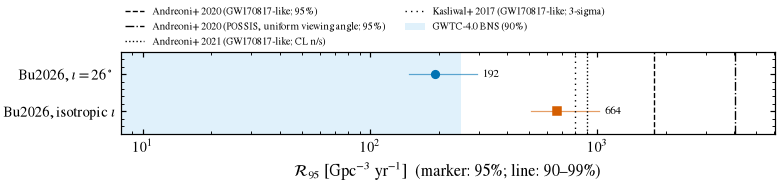

> **Result.** The fixed-angle limit lies inside the GWTC-4 BNS range (7.6–250); the isotropic limit is 2.7× above its upper end. Only a population in which every merger makes a polar-viewed AT2017gfo-like kilonova would be constrained.

In [3]:
SHOW_LITERATURE = ["andreoni2020_gw170817", "andreoni2020_possis_isotropic", "andreoni2021_ztfrest_combined",
                   "kasliwal2017_iptf", "gwtc4_bns_rate"]   # options: L.keys()
fig = F.rate_limits(lim, M, SHOW_LITERATURE); ctx.save(fig, "rate_limits"); plt.show()
gw = L.lookup("gwtc4_bns_rate")
NB.finding(f"The fixed-angle limit lies inside the GWTC-4 BNS range ({gw['low']:g}–{gw['high']:g}); the isotropic limit is "
           f"{lim.loc[ISO, 'r95'] / gw['high']:.1f}× above its upper end. Only a population in which every merger makes a "
           f"polar-viewed AT2017gfo-like kilonova would be constrained.")

## How far does ZTF see? (Fig. 4)

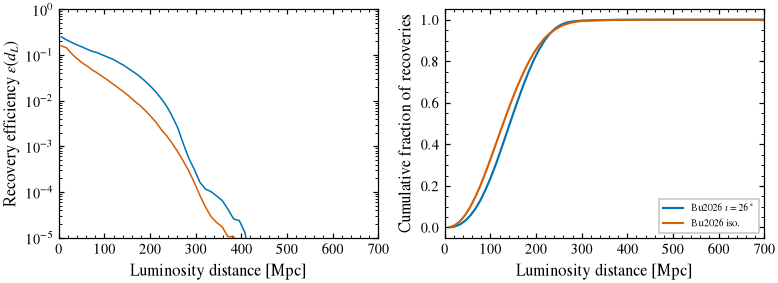

,dL50,dL90,dL99
Bu2026Fixed,143,219,275
Bu2026Vary,128,215,286


> **Result.** Half of the recovered kilonovae are within 143 Mpc and 99% within 275 Mpc; nothing is recovered near the injection boundary $z_{\max} = 0.15$.

In [4]:
fig = F.distance_reach(ctx.zh, runs, M); ctx.save(fig, "distance_reach"); plt.show()
q = pd.DataFrame({m: A.distance_quantiles(ctx.zh, m) for m in M}).T.round(0); display(q)
NB.finding(f"Half of the recovered kilonovae are within {q.loc[FIX, 'dL50']:.0f} Mpc and 99% within {q.loc[FIX, 'dL99']:.0f} Mpc; "
           f"nothing is recovered near the injection boundary $z_{{\\max}} = {runs.z_max.iloc[0]}$.")

## Does the realisation-to-realisation scatter match counting statistics?

In [5]:
chk = []
for m in M:
    g = runs[runs.model == m]; p = g.n_detected.sum() / g.n_simulated.sum()
    chk.append(dict(model=m, observed_sd=g.n_detected.std(ddof=1), binomial_sd=np.sqrt(g.n_simulated.mean() * p * (1 - p))))
chk = pd.DataFrame(chk).set_index("model"); chk["ratio"] = chk.observed_sd / chk.binomial_sd; display(chk.round(2))
NB.finding(f"Observed scatter / binomial expectation = {chk.ratio.min():.2f}–{chk.ratio.max():.2f}: the realisations are "
           "independent and the pooled error bars are pure counting noise.")

,observed_sd,binomial_sd,ratio
model,,,
Bu2026Fixed,42.58,42.89,0.99
Bu2026Vary,24.63,23.22,1.06


> **Result.** Observed scatter / binomial expectation = 0.99–1.06: the realisations are independent and the pooled error bars are pure counting noise.